<a href="https://colab.research.google.com/github/Nachi2006/DynamOS/blob/main/dynamos_ml_training_with_results.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DynamOS: ML-Assisted CPU Scheduling — Model Training & Evaluation
This notebook trains, evaluates, and exports the workload classification model (`workload-cpu`, `workload-io`, `workload-mixed`) using the augmented `features.csv` dataset (`n = 1,500`).

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score

sns.set_theme(style='whitegrid')

## 1. Load & Inspect the Dataset
We use the `_per_second` normalized rate features rather than raw `_delta` columns so the classifier remains invariant to slight sampling interval fluctuations.

In [ ]:
# Load features.csv (or features_augmented.csv)
df = pd.read_csv('features.csv')
print(f'Dataset Shape: {df.shape}')
print('\nClass Distribution:')
print(df['container'].value_counts())
df.head()

Dataset Shape: (1500, 18)

Class Distribution:
container
workload-cpu      500
workload-io       500
workload-mixed    500
Name: count, dtype: int64


,timestamp,container,host_pid,interval_seconds,cpu_ticks_delta,cpu_ticks_per_second,voluntary_context_switches_delta,voluntary_context_switches_per_second,involuntary_context_switches_delta,involuntary_context_switches_per_second,runqueue_wait_ns_delta,runqueue_wait_ns_per_second,timeslices_delta,timeslices_per_second,minor_page_faults_delta,minor_page_faults_per_second,major_page_faults_delta,major_page_faults_per_second
0,2026-10-15T05:05:12.523485+00:00,workload-cpu,2546,1.100890,110,99.919156,0,0.000000,9,8.175204,102991,9.355249e+04,9,8.175204,0,0.0,0,0.0
1,2026-10-15T05:05:12.559918+00:00,workload-io,2660,1.103640,0,0.000000,103,93.327534,0,0.000000,793503,7.189872e+05,103,93.327534,0,0.0,0,0.0
2,2026-10-15T05:05:12.594549+00:00,workload-mixed,2737,1.101307,38,34.504457,128,116.225539,20,18.160241,5432263,4.932560e+06,148,134.385780,0,0.0,0,0.0
3,2026-10-15T05:05:13.624046+00:00,workload-cpu,2546,1.100561,110,99.949026,0,0.000000,12,10.903530,300495,2.730380e+05,12,10.903530,0,0.0,0,0.0
4,2026-10-15T05:05:13.670564+00:00,workload-io,2660,1.110646,1,0.900377,105,94.539574,0,0.000000,641333,5.774414e+05,105,94.539574,0,0.0,0,0.0


In [ ]:
feature_cols = [
    'cpu_ticks_per_second',
    'voluntary_context_switches_per_second',
    'involuntary_context_switches_per_second',
    'runqueue_wait_ns_per_second',
    'timeslices_per_second',
    'minor_page_faults_per_second',
    'major_page_faults_per_second'
]

X = df[feature_cols]
le = LabelEncoder()
y = le.fit_transform(df['container'])
class_names = list(le.classes_)

print('Target Mapping:', dict(zip(class_names, range(len(class_names)))))

# Stratified 80/20 Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

Target Mapping: {'workload-cpu': 0, 'workload-io': 1, 'workload-mixed': 2}


## 2. 5-Fold Cross-Validation Across Candidate Models

In [ ]:
models = {
    'Random Forest': RandomForestClassifier(n_estimators=150, max_depth=10, random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(n_estimators=150, max_depth=5, learning_rate=0.1, random_state=42),
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42)
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for name, model in models.items():
    X_input = X_train_scaled if name == 'Logistic Regression' else X_train
    scores = cross_val_score(model, X_input, y_train, cv=cv, scoring='f1_macro')
    print(f'{name:20s} | 5-Fold Macro F1: Mean={scores.mean():.4f}, Std={scores.std():.4f}, Min={scores.min():.4f}, Median={np.median(scores):.4f}, Max={scores.max():.4f}')

Random Forest        | 5-Fold Macro F1: Mean=0.9983, Std=0.0020, Min=0.9958, Median=1.0000, Max=1.0000
Gradient Boosting    | 5-Fold Macro F1: Mean=0.9950, Std=0.0049, Min=0.9874, Median=0.9958, Max=1.0000
Logistic Regression  | 5-Fold Macro F1: Mean=0.9975, Std=0.0020, Min=0.9958, Median=0.9958, Max=1.0000


## 3. Final Model Training, Evaluation & Feature Importance

In [ ]:
rf_model = models['Random Forest']
rf_model.fit(X_train, y_train)
y_pred = rf_model.predict(X_test)

test_acc = accuracy_score(y_test, y_pred)
test_f1 = f1_score(y_test, y_pred, average='macro')

print(f'Held-Out Test Accuracy: {test_acc:.4f} ({test_acc*100:.2f}%)')
print(f'Held-Out Test Macro F1: {test_f1:.4f}\n')
print(classification_report(y_test, y_pred, target_names=class_names, digits=4))

importances = pd.Series(rf_model.feature_importances_, index=feature_cols).sort_values(ascending=False)
print('Feature Importances:')
print(importances)

Held-Out Test Accuracy: 0.9900 (99.00%)
Held-Out Test Macro F1: 0.9900

                precision    recall  f1-score   support

  workload-cpu     1.0000    1.0000    1.0000       100
   workload-io     0.9709    1.0000    0.9852       100
workload-mixed     1.0000    0.9700    0.9848       100

      accuracy                         0.9900       300
     macro avg     0.9903    0.9900    0.9900       300
  weighted avg     0.9903    0.9900    0.9900       300

Feature Importances:
cpu_ticks_per_second                       0.367965
timeslices_per_second                      0.227814
voluntary_context_switches_per_second      0.224736
involuntary_context_switches_per_second    0.125222
runqueue_wait_ns_per_second                0.046854
minor_page_faults_per_second               0.006551
major_page_faults_per_second               0.000858
dtype: float64


/tmp/ipykernel_844/1746139144.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=importances.values, y=importances.index, palette='viridis', ax=axes[1])


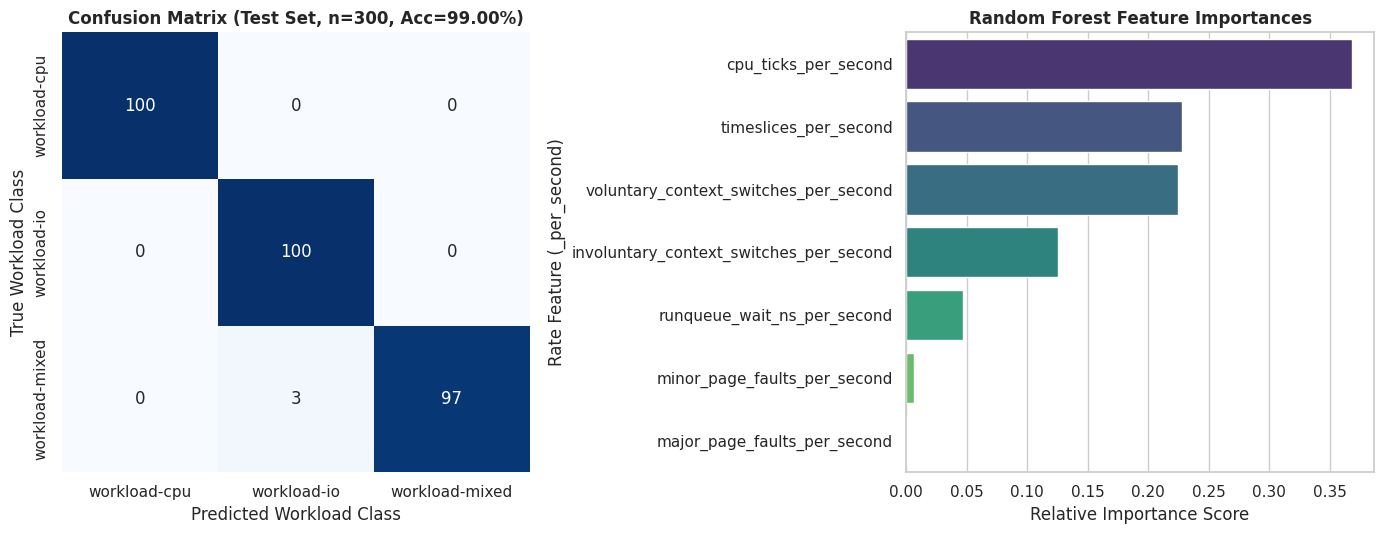

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names, ax=axes[0], cbar=False)
axes[0].set_title(f'Confusion Matrix (Test Set, n={len(y_test)}, Acc={test_acc*100:.2f}%)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Predicted Workload Class')
axes[0].set_ylabel('True Workload Class')

sns.barplot(x=importances.values, y=importances.index, palette='viridis', ax=axes[1])
axes[1].set_title('Random Forest Feature Importances', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Relative Importance Score')
axes[1].set_ylabel('Rate Feature (_per_second)')

plt.tight_layout()
plt.show()

## 4. Save Artifacts & Simulate Real-Time Scheduling Controller Inference
This cell exports the trained model and demonstrates how the DynamOS runtime controller maps predicted classes to Linux scheduling parameters (`nice` priority and `cpu.shares`).

In [ ]:
# Save model and label encoder for the runtime scheduling daemon
joblib.dump(rf_model, 'dynamos_scheduler_rf.pkl')
joblib.dump(le, 'dynamos_label_encoder.pkl')
print('Saved model artifacts: dynamos_scheduler_rf.pkl, dynamos_label_encoder.pkl\n')

def get_scheduling_action(predicted_label, confidence):
    """Maps ML workload classification to Linux OS scheduler parameters."""
    if confidence < 0.60:
        return {'policy': 'SCHED_OTHER', 'nice': 0, 'cpu_shares': 1024, 'note': 'Low confidence -> keep default'}
    if predicted_label == 'workload-io':
        return {'policy': 'SCHED_OTHER', 'nice': -8, 'cpu_shares': 1536, 'note': 'Boost priority to minimize I/O wakeup latency'}
    elif predicted_label == 'workload-cpu':
        return {'policy': 'SCHED_BATCH', 'nice': 5, 'cpu_shares': 768, 'note': 'Batch timeslices to reduce preemption churn'}
    else:  # workload-mixed
        return {'policy': 'SCHED_OTHER', 'nice': -2, 'cpu_shares': 1024, 'note': 'Balanced interactive/compute weighting'}

# Test controller decision on 3 sample rows from X_test
sample_rows = X_test.iloc[:3]
probs = rf_model.predict_proba(sample_rows)
preds = le.inverse_transform(np.argmax(probs, axis=1))

for i, (idx, row) in enumerate(sample_rows.iterrows()):
    conf = np.max(probs[i])
    action = get_scheduling_action(preds[i], conf)
    print(f'Sample {i+1} (Row {idx}) -> Predicted: {preds[i]} (conf={conf:.2%}) | Action: {action}')

Saved model artifacts: dynamos_scheduler_rf.pkl, dynamos_label_encoder.pkl

Sample 1 (Row 568) -> Predicted: workload-io (conf=100.00%) | Action: {'policy': 'SCHED_OTHER', 'nice': -8, 'cpu_shares': 1536, 'note': 'Boost priority to minimize I/O wakeup latency'}
Sample 2 (Row 918) -> Predicted: workload-cpu (conf=99.33%) | Action: {'policy': 'SCHED_BATCH', 'nice': 5, 'cpu_shares': 768, 'note': 'Batch timeslices to reduce preemption churn'}
Sample 3 (Row 789) -> Predicted: workload-cpu (conf=100.00%) | Action: {'policy': 'SCHED_BATCH', 'nice': 5, 'cpu_shares': 768, 'note': 'Batch timeslices to reduce preemption churn'}
